Using Colab cache for faster access to the 'telco-customer-churn' dataset.


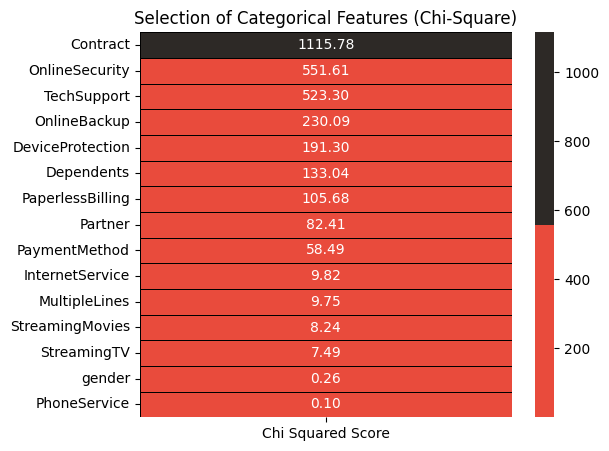

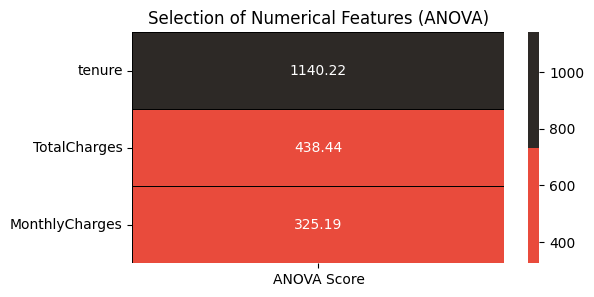

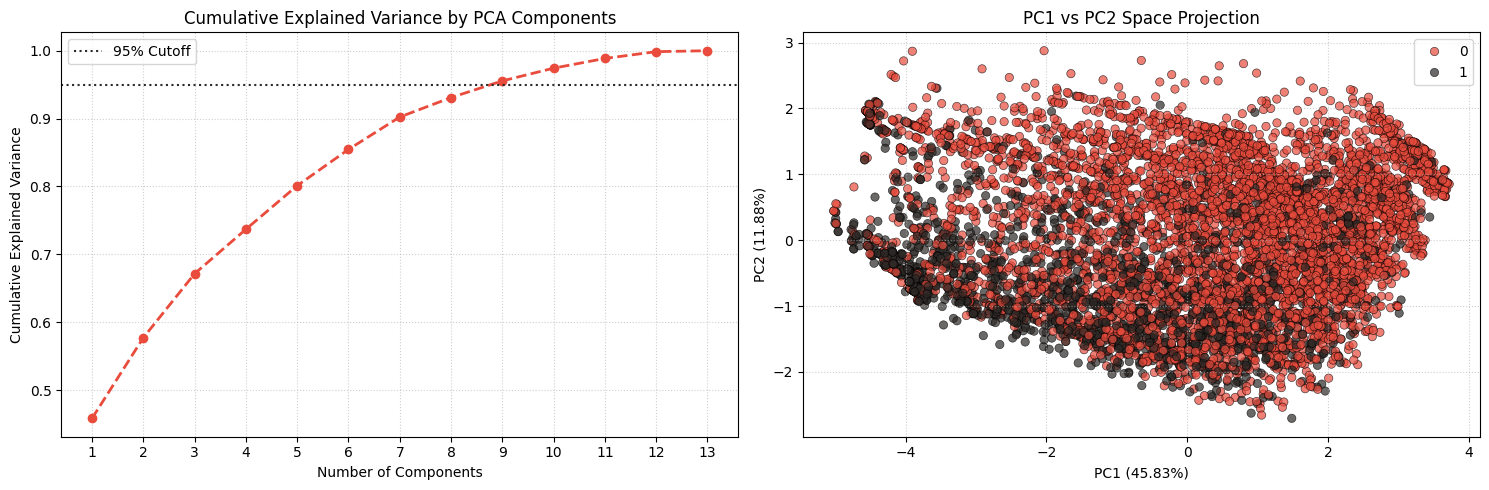

=== PCA Explained Variance Summary ===
PC1: 45.83% variance explained (Cumulative: 45.83%)
PC2: 11.88% variance explained (Cumulative: 57.71%)
PC3: 9.43% variance explained (Cumulative: 67.15%)
PC4: 6.54% variance explained (Cumulative: 73.69%)
PC5: 6.42% variance explained (Cumulative: 80.12%)
PC6: 5.34% variance explained (Cumulative: 85.46%)
PC7: 4.77% variance explained (Cumulative: 90.23%)
PC8: 2.87% variance explained (Cumulative: 93.09%)
PC9: 2.46% variance explained (Cumulative: 95.56%)
PC10: 1.87% variance explained (Cumulative: 97.43%)
PC11: 1.43% variance explained (Cumulative: 98.86%)
PC12: 1.00% variance explained (Cumulative: 99.86%)
PC13: 0.14% variance explained (Cumulative: 100.00%)

Original dimensions: 13
Components for ≥95% variance: 9
Dimensionality reduction compression: 30.8%


In [6]:
import os
import kagglehub
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, chi2, f_classif

# Dataset import as in DSV project.ipynb
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
data = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))

# Use the processed 'df' dataset from kernel state
df1 = df.copy()

# Colors matching the notebook palette
colors = ["#E94B3C", "#2D2926"]

# -------------------------------------------------------------
# 1. FEATURE SELECTION
# -------------------------------------------------------------

# Categorical Feature Selection using Chi-Square (Η) test
cat_cols = [
    col
    for col in categorical_features
    if col in df1.columns and col != "Churn"
]
X_cat = df1[cat_cols]
y = df1["Churn"]

best_cat = SelectKBest(score_func=chi2, k="all")
fit_cat = best_cat.fit(X_cat, y)

cat_scores = pd.DataFrame(
    data=fit_cat.scores_, index=cat_cols, columns=["Chi Squared Score"]
).sort_values(by="Chi Squared Score", ascending=False)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cat_scores,
    annot=True,
    cmap=colors,
    linewidths=0.4,
    linecolor="black",
    fmt=".2f",
)
plt.title("Selection of Categorical Features (Chi-Square)")
plt.show()

# Numerical Feature Selection using ANOVA F-score
num_cols = [col for col in numerical_features if col in df1.columns]
X_num = df1[num_cols]

best_num = SelectKBest(score_func=f_classif, k="all")
fit_num = best_num.fit(X_num, y)

num_scores = pd.DataFrame(
    data=fit_num.scores_, index=num_cols, columns=["ANOVA Score"]
).sort_values(by="ANOVA Score", ascending=False)

plt.figure(figsize=(6, 3))
sns.heatmap(
    num_scores,
    annot=True,
    cmap=colors,
    linewidths=0.4,
    linecolor="black",
    fmt=".2f",
)
plt.title("Selection of Numerical Features (ANOVA)")
plt.show()

# Drop lowest ranking / low-impact features identified from feature selection
drop_cols = [
    "PhoneService",
    "gender",
    "StreamingTV",
    "StreamingMovies",
    "MultipleLines",
    "InternetService",
]
df1.drop(columns=[col for col in drop_cols if col in df1.columns], inplace=True)

# -------------------------------------------------------------
# 2. PRINCIPAL COMPONENT ANALYSIS (PCA)
# -------------------------------------------------------------

# Separate features and target
X_pca = df1.drop(columns=["Churn"]).values
y_pca = df1["Churn"].values
n_features = X_pca.shape[1]

# Fit PCA across all remaining dimensions
pca = PCA(n_components=n_features, random_state=42)
X_transformed = pca.fit_transform(X_pca)

cum_variance = np.cumsum(pca.explained_variance_ratio_)

# -------------------------------------------------------------
# 3. VISUALIZING VARIANCE & PROJECTION
# -------------------------------------------------------------

plt.figure(figsize=(15, 5))

# Plot 1: Cumulative Explained Variance
plt.subplot(1, 2, 1)
plt.plot(
    range(1, n_features + 1),
    cum_variance,
    marker="o",
    linestyle="--",
    color=colors[0],
    linewidth=2,
)
plt.axhline(y=0.95, color=colors[1], linestyle=":", label="95% Cutoff")
plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, n_features + 1))
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

# Plot 2: PC1 vs PC2 2D Projection
plt.subplot(1, 2, 2)
sns.scatterplot(
    x=X_transformed[:, 0],
    y=X_transformed[:, 1],
    hue=y_pca,
    palette=colors,
    edgecolor="black",
    alpha=0.7,
)
plt.title("PC1 vs PC2 Space Projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Variance Explained Summary Table
print("=== PCA Explained Variance Summary ===")
for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(
        f"PC{i+1}: {ratio:.2%} variance explained (Cumulative: {cum_variance[i]:.2%})"
    )

n_comp_95 = np.argmax(cum_variance >= 0.95) + 1
print(f"\nOriginal dimensions: {n_features}")
print(f"Components for ≥95% variance: {n_comp_95}")
print(
    f"Dimensionality reduction compression: {((n_features - n_comp_95) / n_features):.1%}"
)